**Drug Repurposing Candidate Identification Using Differential Gene Expression and Drug–Gene Interaction Databases**

End-to-End Bioinformatics Pipeline Using Databricks and Python

**Author:** Ume Abiha

**Project Overview**

This project integrates differential gene expression results from a TCGA-BRCA breast cancer analysis with drug–gene interaction data from the Drug Gene Interaction Database (DGIdb).
The objective is to identify significantly dysregulated genes, determine which of these genes are druggable, and prioritize existing drugs that may represent computational candidates for drug repurposing.
This workflow demonstrates the integration of transcriptomic analysis, statistical testing, biological databases, and network analysis using Python in Databricks.

**1. Load Differential Gene Expression Results**

In [0]:
import os
import pandas as pd
import numpy as np

RES_DIR = "../results"
FIG_DIR = "../figures"
os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# Differential expression results exported by the TCGA-BRCA analysis project
# (github.com/abihaume/tcga-brca-gene-expression-analysis).
# Log2FC = mean log2 expression in tumor - mean log2 expression in normal.
dge_df = pd.read_csv(f"{RES_DIR}/dge_results.csv")

print("Dataset Shape:", dge_df.shape)

dge_df.head()

Dataset Shape: (20530, 9)


,Gene,Tumor_Mean,Normal_Mean,Log2FC,P_Value,FDR,NegLog10_P,NegLog10_FDR,Significance
0,KRTAP13-4,0.015289,0.418334,-0.403045,6.218631e-73,1.276685e-68,72.206305,67.893916,Not Significant
1,AADACL2,0.158196,1.423585,-1.265389,2.309154e-70,2.370347e-66,69.636547,65.625188,Downregulated
2,CPA1,0.745907,4.601289,-3.855382,7.199003e-69,4.926518e-65,68.142728,64.307460,Downregulated
3,LOC572558,0.613613,3.707292,-3.093679,1.631806e-68,8.375246e-65,67.787331,64.077002,Downregulated
4,CA4,1.500376,8.104417,-6.604041,2.377527e-68,9.762124e-65,67.623875,64.010456,Downregulated


In [0]:
dge_df.describe()

,Tumor_Mean,Normal_Mean,Log2FC,P_Value,FDR,NegLog10_P,NegLog10_FDR
count,20530.000000,20530.000000,20530.000000,2.053000e+04,2.053000e+04,20530.000000,20530.000000
mean,6.420177,6.571033,-0.150856,9.811985e-02,1.057061e-01,14.263067,13.828960
std,3.913483,3.914258,1.014474,2.310476e-01,2.410388e-01,15.734750,15.311967
min,0.000000,0.000000,-7.257793,6.218631e-73,1.276685e-68,-0.000000,-0.000000
25%,2.736453,3.114874,-0.485341,4.751100e-23,1.900162e-22,1.724076,1.599144
50%,7.583228,7.739818,-0.006389,1.055487e-08,2.110872e-08,7.976547,7.675538
75%,9.603595,9.683428,0.325454,1.887663e-02,2.516843e-02,22.323207,21.721211
max,16.466587,16.947503,6.774244,1.000000e+00,1.000000e+00,72.206305,67.893916


**2. Apply False Discovery Rate (FDR) Correction**

RNA-seq experiments test over 20,000 genes simultaneously. To reduce false positive findings caused by multiple hypothesis testing, the Benjamini–Hochberg False Discovery Rate (FDR) correction is applied to all p-values. Genes with an adjusted p-value below 0.05 are considered statistically significant.

In [0]:
from scipy.stats import false_discovery_control

In [0]:
# Apply Benjamini-Hochberg False Discovery Rate correction

dge_df["Adjusted_P"] = false_discovery_control(
    dge_df["P_Value"],
    method="bh"
)

print("FDR correction applied successfully!")

dge_df.head()

FDR correction applied successfully!


,Gene,Tumor_Mean,Normal_Mean,Log2FC,P_Value,FDR,NegLog10_P,NegLog10_FDR,Significance,Adjusted_P
0,KRTAP13-4,0.015289,0.418334,-0.403045,6.218631e-73,1.276685e-68,72.206305,67.893916,Not Significant,1.276685e-68
1,AADACL2,0.158196,1.423585,-1.265389,2.309154e-70,2.370347e-66,69.636547,65.625188,Downregulated,2.370347e-66
2,CPA1,0.745907,4.601289,-3.855382,7.199003e-69,4.926518e-65,68.142728,64.307460,Downregulated,4.926518e-65
3,LOC572558,0.613613,3.707292,-3.093679,1.631806e-68,8.375246e-65,67.787331,64.077002,Downregulated,8.375246e-65
4,CA4,1.500376,8.104417,-6.604041,2.377527e-68,9.762124e-65,67.623875,64.010456,Downregulated,9.762124e-65


**3. Filter Significant Differentially Expressed Genes**

In [0]:
# Keep genes significant after FDR correction

significant_genes = dge_df[dge_df["Adjusted_P"] < 0.05]

print("Number of significant genes after FDR correction:")
print(significant_genes.shape[0])

Number of significant genes after FDR correction:
15890


In [0]:
# Display the most significant genes
significant_genes.sort_values("Adjusted_P").head(10)

,Gene,Tumor_Mean,Normal_Mean,Log2FC,P_Value,FDR,NegLog10_P,NegLog10_FDR,Significance,Adjusted_P
0,KRTAP13-4,0.015289,0.418334,-0.403045,6.218631e-73,1.276685e-68,72.206305,67.893916,Not Significant,1.276685e-68
1,AADACL2,0.158196,1.423585,-1.265389,2.309154e-70,2.370347e-66,69.636547,65.625188,Downregulated,2.370347e-66
2,CPA1,0.745907,4.601289,-3.855382,7.199003e-69,4.926518e-65,68.142728,64.307460,Downregulated,4.926518e-65
3,LOC572558,0.613613,3.707292,-3.093679,1.631806e-68,8.375246e-65,67.787331,64.077002,Downregulated,8.375246e-65
4,CA4,1.500376,8.104417,-6.604041,2.377527e-68,9.762124e-65,67.623875,64.010456,Downregulated,9.762124e-65
5,FIGF,3.033205,9.188756,-6.155552,5.836389e-68,1.997018e-64,67.233856,63.699618,Downregulated,1.997018e-64
6,SDPR,6.672736,11.370902,-4.698165,1.023778e-67,2.625421e-64,66.989794,63.580801,Downregulated,2.625421e-64
7,MMP11,12.315019,6.493440,5.821579,1.123838e-67,2.625421e-64,66.949296,63.580801,Upregulated,2.625421e-64
8,CD300LG,3.833923,10.300038,-6.466115,1.150940e-67,2.625421e-64,66.938947,63.580801,Downregulated,2.625421e-64
9,ADAMTS5,7.636122,11.178399,-3.542277,2.332673e-67,4.788978e-64,66.632146,63.319757,Downregulated,4.788978e-64


In [0]:
filtered_genes = dge_df[
    (dge_df["Adjusted_P"] < 0.05) &
    (abs(dge_df["Log2FC"]) > 1)
]

print("Number of filtered genes:")
print(filtered_genes.shape[0])

Number of filtered genes:
4225


In [0]:
filtered_genes = filtered_genes.sort_values(
    "Adjusted_P"
)

filtered_genes.head(20)

,Gene,Tumor_Mean,Normal_Mean,Log2FC,P_Value,FDR,NegLog10_P,NegLog10_FDR,Significance,Adjusted_P
1,AADACL2,0.158196,1.423585,-1.265389,2.309154e-70,2.370347e-66,69.636547,65.625188,Downregulated,2.370347e-66
2,CPA1,0.745907,4.601289,-3.855382,7.199003e-69,4.926518e-65,68.142728,64.307460,Downregulated,4.926518e-65
3,LOC572558,0.613613,3.707292,-3.093679,1.631806e-68,8.375246e-65,67.787331,64.077002,Downregulated,8.375246e-65
4,CA4,1.500376,8.104417,-6.604041,2.377527e-68,9.762124e-65,67.623875,64.010456,Downregulated,9.762124e-65
5,FIGF,3.033205,9.188756,-6.155552,5.836389e-68,1.997018e-64,67.233856,63.699618,Downregulated,1.997018e-64
6,SDPR,6.672736,11.370902,-4.698165,1.023778e-67,2.625421e-64,66.989794,63.580801,Downregulated,2.625421e-64
7,MMP11,12.315019,6.493440,5.821579,1.123838e-67,2.625421e-64,66.949296,63.580801,Upregulated,2.625421e-64
8,CD300LG,3.833923,10.300038,-6.466115,1.150940e-67,2.625421e-64,66.938947,63.580801,Downregulated,2.625421e-64
9,ADAMTS5,7.636122,11.178399,-3.542277,2.332673e-67,4.788978e-64,66.632146,63.319757,Downregulated,4.788978e-64
10,MAMDC2,5.899215,9.842923,-3.943708,5.623039e-67,1.049463e-63,66.250029,62.979033,Downregulated,1.049463e-63


In [0]:
filtered_genes.to_csv(
    f"{RES_DIR}/filtered_dge_genes.csv",
    index=False
)

print("Filtered genes saved successfully!")

Filtered genes saved successfully!


In [0]:
# Thousands of genes have extremely small adjusted p-values,
# so ranking by p-value alone is not very informative.
# Rank by the size of the change instead.

upregulated = filtered_genes[filtered_genes["Log2FC"] > 0].sort_values("Log2FC", ascending=False)
downregulated = filtered_genes[filtered_genes["Log2FC"] < 0].sort_values("Log2FC")

print("Upregulated genes:", len(upregulated))
print("Downregulated genes:", len(downregulated))

Upregulated genes: 1412
Downregulated genes: 2813


 **4. Select the Top 100 Differentially Expressed Genes**

We take the 50 most upregulated and the 50 most downregulated genes, so both directions are represented.

In [0]:
top100_genes = pd.concat([upregulated.head(50), downregulated.head(50)])
print("Top genes selected:", len(top100_genes))

Top genes selected: 100


In [0]:
gene_list = top100_genes["Gene"].tolist()
gene_list[:20]

['COL10A1',
 'COL11A1',
 'MMP11',
 'MMP13',
 'CST1',
 'MMP1',
 'PPAPDC1A',
 'COMP',
 'NEK2',
 'PKMYT1',
 'S100P',
 'KIF4A',
 'UBE2C',
 'IBSP',
 'TNNT1',
 'PITX1',
 'IQGAP3',
 'NUF2',
 'GRM4',
 'MELK']

In [0]:
top100_genes.to_csv(
    f"{RES_DIR}/top100_dge_genes.csv",
    index=False
)
print("Top 100 genes saved.")

Top 100 genes saved.


In [0]:
%pip install requests

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


**5. Retrieve Drug–Gene Interactions from DGIdb**

In [0]:
import requests
import pandas as pd

#We'll first test the API using one gene before querying all 100.

gene = "IBSP"

In [0]:
query = """
{
  genes(names: ["IBSP"]) {
    nodes {
      name
      interactions {
        drug {
          name
        }
        interactionTypes {
          type
        }
        sources {
          sourceDbName
        }
      }
    }
  }
}
"""

In [0]:
url = "https://dgidb.org/api/graphql"

response = requests.post(
    url,
    json={"query": query}
)

print(response.status_code)

200


In [0]:
data = response.json()
data

{'data': {'genes': {'nodes': [{'name': 'IBSP',
     'interactions': [{'drug': {'name': 'CYCLOSPORINE'},
       'interactionTypes': [],
       'sources': [{'sourceDbName': 'NCI'}]},
      {'drug': {'name': 'INSULIN, REGULAR, HUMAN'},
       'interactionTypes': [],
       'sources': [{'sourceDbName': 'NCI'}]},
      {'drug': {'name': 'TNF-ALPHA'},
       'interactionTypes': [],
       'sources': [{'sourceDbName': 'NCI'}]},
      {'drug': {'name': 'DAIDZEIN'},
       'interactionTypes': [],
       'sources': [{'sourceDbName': 'NCI'}]},
      {'drug': {'name': 'ZOLEDRONIC ACID ANHYDROUS'},
       'interactionTypes': [],
       'sources': [{'sourceDbName': 'NCI'}]}]}]}}}

In [0]:
import requests
import pandas as pd

url = "https://dgidb.org/api/graphql"

In [0]:
# Query all genes in ONE request: DGIdb accepts a list of gene names
names = ", ".join(f'"{g}"' for g in gene_list)

query = f"""
{{
  genes(names: [{names}]) {{
    nodes {{
      name
      interactions {{
        drug {{
          name
        }}
        interactionTypes {{
          type
        }}
        sources {{
          sourceDbName
        }}
      }}
    }}
  }}
}}
"""

response = requests.post(url, json={"query": query}, timeout=120)
response.raise_for_status()

data = response.json()

if "errors" in data:
    raise RuntimeError(data["errors"])

drug_results = []

for node in data["data"]["genes"]["nodes"]:

    for interaction in node["interactions"]:

        # Keep ALL interaction types and sources, not only the first one
        types = sorted({t["type"] for t in interaction["interactionTypes"]})
        sources = sorted({s["sourceDbName"] for s in interaction["sources"]})

        drug_results.append(
            {
                "Gene": node["name"],
                "Drug": interaction["drug"]["name"],
                "Interaction": "; ".join(types) if types else "Unknown",
                "Source": "; ".join(sources) if sources else "Unknown"
            }
        )

found = {node["name"] for node in data["data"]["genes"]["nodes"]}
print("Genes found in DGIdb:", len(found), "of", len(gene_list))

Genes found in DGIdb: 69 of 100


In [0]:
drug_df = pd.DataFrame(drug_results)
drug_df.head()

,Gene,Drug,Interaction,Source
0,CA4,CURCUMIN,Unknown,Drug Repurposing Hub
1,CA4,HYDROFLUMETHIAZIDE,Unknown,Drug Repurposing Hub
2,CA4,TOPIRAMATE,inhibitor,ChEMBL; Drug Repurposing Hub; GuideToPharmacol...
3,CA4,CHLOROTHIAZIDE,Unknown,Drug Repurposing Hub; TEND; TdgClinicalTrial
4,CA4,COUMARIN,Unknown,Drug Repurposing Hub


In [0]:
print("Total drug-gene interactions:")
print(len(drug_df))

Total drug-gene interactions:
816


In [0]:
drug_df.to_csv(
    f"{RES_DIR}/drug_gene_interactions.csv",
    index=False
)
print("Drug interaction table saved.")

Drug interaction table saved.


In [0]:
# Inspect the raw interaction table

print("Raw rows:", len(drug_df))
print("Missing values:")
print(drug_df.isna().sum())

print("\nDuplicate rows:")
print(drug_df.duplicated().sum())

Raw rows: 816
Missing values:
Gene           0
Drug           0
Interaction    0
Source         0
dtype: int64

Duplicate rows:
0


**6. Clean Drug–Gene Interaction Data**

In [0]:
drug_clean_df = drug_df.copy()

drug_clean_df["Gene"] = (
    drug_clean_df["Gene"]
    .astype(str)
    .str.strip()
    .str.upper()
)

drug_clean_df["Drug"] = (
    drug_clean_df["Drug"]
    .astype(str)
    .str.strip()
    .str.upper()
)

drug_clean_df["Interaction"] = (
    drug_clean_df["Interaction"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .str.lower()
)

drug_clean_df["Source"] = (
    drug_clean_df["Source"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

# Remove exact duplicate records
drug_clean_df = drug_clean_df.drop_duplicates().reset_index(drop=True)

print("Rows after cleaning:", len(drug_clean_df))

drug_clean_df.head()

Rows after cleaning: 816


,Gene,Drug,Interaction,Source
0,CA4,CURCUMIN,unknown,Drug Repurposing Hub
1,CA4,HYDROFLUMETHIAZIDE,unknown,Drug Repurposing Hub
2,CA4,TOPIRAMATE,inhibitor,ChEMBL; Drug Repurposing Hub; GuideToPharmacol...
3,CA4,CHLOROTHIAZIDE,unknown,Drug Repurposing Hub; TEND; TdgClinicalTrial
4,CA4,COUMARIN,unknown,Drug Repurposing Hub


In [0]:
# Select relevant differential-expression information

gene_metadata = top100_genes[
    ["Gene", "Log2FC", "Adjusted_P"]
].copy()

gene_metadata["Gene"] = (
    gene_metadata["Gene"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Merge expression statistics with DGIdb results
drug_clean_df = drug_clean_df.merge(
    gene_metadata,
    on="Gene",
    how="left"
)

drug_clean_df.head()

,Gene,Drug,Interaction,Source,Log2FC,Adjusted_P
0,CA4,CURCUMIN,unknown,Drug Repurposing Hub,-6.604041,9.762124e-65
1,CA4,HYDROFLUMETHIAZIDE,unknown,Drug Repurposing Hub,-6.604041,9.762124e-65
2,CA4,TOPIRAMATE,inhibitor,ChEMBL; Drug Repurposing Hub; GuideToPharmacol...,-6.604041,9.762124e-65
3,CA4,CHLOROTHIAZIDE,unknown,Drug Repurposing Hub; TEND; TdgClinicalTrial,-6.604041,9.762124e-65
4,CA4,COUMARIN,unknown,Drug Repurposing Hub,-6.604041,9.762124e-65


In [0]:
import numpy as np

drug_clean_df["Expression_Direction"] = np.where(
    drug_clean_df["Log2FC"] > 0,
    "Upregulated",
    "Downregulated"
)

drug_clean_df[
    [
        "Gene",
        "Drug",
        "Interaction",
        "Source",
        "Log2FC",
        "Adjusted_P",
        "Expression_Direction"
    ]
].head(10)

,Gene,Drug,Interaction,Source,Log2FC,Adjusted_P,Expression_Direction
0,CA4,CURCUMIN,unknown,Drug Repurposing Hub,-6.604041,9.762124e-65,Downregulated
1,CA4,HYDROFLUMETHIAZIDE,unknown,Drug Repurposing Hub,-6.604041,9.762124e-65,Downregulated
2,CA4,TOPIRAMATE,inhibitor,ChEMBL; Drug Repurposing Hub; GuideToPharmacol...,-6.604041,9.762124e-65,Downregulated
3,CA4,CHLOROTHIAZIDE,unknown,Drug Repurposing Hub; TEND; TdgClinicalTrial,-6.604041,9.762124e-65,Downregulated
4,CA4,COUMARIN,unknown,Drug Repurposing Hub,-6.604041,9.762124e-65,Downregulated
5,CA4,ETHOXZOLAMIDE,inhibitor,ChEMBL; Drug Repurposing Hub,-6.604041,9.762124e-65,Downregulated
6,CA4,ZONISAMIDE,unknown,Drug Repurposing Hub,-6.604041,9.762124e-65,Downregulated
7,CA4,ACETAZOLAMIDE,inhibitor,ChEMBL; Drug Repurposing Hub; GuideToPharmacology,-6.604041,9.762124e-65,Downregulated
8,CA4,SULTHIAME,inhibitor,ChEMBL,-6.604041,9.762124e-65,Downregulated
9,CA4,SPARFOSIC ACID,unknown,Drug Repurposing Hub,-6.604041,9.762124e-65,Downregulated


**7. Drug Repurposing Analysis**

This section summarizes the druggability of the top differentially expressed genes by examining known drug–gene interactions retrieved from DGIdb. We evaluate how many genes have known drug interactions, identify the most druggable genes, determine drugs targeting multiple genes, and summarize interaction types.

 How many of the top 100 genes had interactions?

In [0]:
queried_gene_count = len(set(gene_list))
genes_with_drugs = drug_clean_df["Gene"].nunique()
genes_without_drugs = queried_gene_count - genes_with_drugs

druggable_percentage = (
    genes_with_drugs / queried_gene_count
) * 100

print("Genes queried:", queried_gene_count)
print("Genes with known interactions:", genes_with_drugs)
print("Genes without known interactions:", genes_without_drugs)
print(f"Percentage with known interactions: {druggable_percentage:.1f}%")

Genes queried: 100
Genes with known interactions: 46
Genes without known interactions: 54
Percentage with known interactions: 46.0%


Which genes have the most associated drugs?

In [0]:
drugs_per_gene = (
    drug_clean_df
    .groupby("Gene")["Drug"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="Number_of_Drugs")
)

drugs_per_gene.head(15)

,Gene,Number_of_Drugs
0,PLK1,190
1,TOP2A,132
2,BIRC5,66
3,NPY2R,36
4,MMP1,32
5,GRM4,32
6,APOB,26
7,CA4,26
8,MMP13,25
9,LEP,24


In [0]:
genes_per_drug = (
    drug_clean_df
    .groupby("Drug")["Gene"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="Number_of_Genes")
)

multi_gene_drugs = genes_per_drug[
    genes_per_drug["Number_of_Genes"] > 1
].copy()

print("Unique drugs:", drug_clean_df["Drug"].nunique())
print("Drugs targeting more than one selected gene:", len(multi_gene_drugs))

multi_gene_drugs.head(20)

Unique drugs: 720
Drugs targeting more than one selected gene: 59


,Drug,Number_of_Genes
0,FLUOROURACIL,4
1,"INSULIN, REGULAR, HUMAN",4
2,CYTARABINE,3
3,SP-600125,3
4,CISPLATIN,3
5,QUERCETIN,3
6,NVP-TAE684,3
7,DEXAMETHASONE,3
8,MARIMASTAT,3
9,GEFITINIB,3


In [0]:
drug_target_summary = (
    drug_clean_df
    .groupby("Drug")
    .agg(
        Number_of_Genes=("Gene", "nunique"),
        Target_Genes=("Gene", lambda x: ", ".join(sorted(set(x)))),
        Sources=("Source", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
    .sort_values(
        "Number_of_Genes",
        ascending=False
    )
)

drug_target_summary.head(20)

,Drug,Number_of_Genes,Target_Genes,Sources
348,FLUOROURACIL,4,"BIRC5, CDC25C, EXO1, TOP2A","ClinPGx, NCI"
412,"INSULIN, REGULAR, HUMAN",4,"ADIPOQ, AQP7, IBSP, TDO2",NCI
269,CYTARABINE,3,"ADH1A, BIRC5, RRM2","ClinPGx, NCI"
622,SP-600125,3,"MELK, NEK2, PBK",DTC
230,CISPLATIN,3,"ADH1C, BIRC5, CDC25C","ClinPGx, NCI"
580,QUERCETIN,3,"APOB, CDC25C, TOP2A","DTC, NCI"
518,NVP-TAE684,3,"MELK, NEK2, PLK1",DTC
282,DEXAMETHASONE,3,"APOB, BIRC5, TDO2",NCI
457,MARIMASTAT,3,"MMP1, MMP11, MMP13",ChEMBL; Drug Repurposing Hub; GuideToPharmacol...
362,GEFITINIB,3,"CEACAM5, PBK, UHRF1","CIViC, ClinPGx, NCI"


In [0]:
interaction_counts = (
    drug_clean_df["Interaction"]
    .value_counts(dropna=False)
    .reset_index()
)

interaction_counts.columns = [
    "Interaction_Type",
    "Count"
]

interaction_counts

,Interaction_Type,Count
0,unknown,603
1,inhibitor,145
2,agonist,33
3,modulator,20
4,binder,7
5,cleavage,2
6,antibody,2
7,positive modulator,1
8,vaccine,1
9,other/unknown,1


In [0]:
defined_interactions = drug_clean_df[
    drug_clean_df["Interaction"] != "unknown"
].copy()

print("Interactions with a defined mechanism:", len(defined_interactions))

defined_interactions[
    [
        "Gene",
        "Drug",
        "Interaction",
        "Expression_Direction",
        "Log2FC"
    ]
].head(20)

Interactions with a defined mechanism: 213


,Gene,Drug,Interaction,Expression_Direction,Log2FC
2,CA4,TOPIRAMATE,inhibitor,Downregulated,-6.604041
5,CA4,ETHOXZOLAMIDE,inhibitor,Downregulated,-6.604041
7,CA4,ACETAZOLAMIDE,inhibitor,Downregulated,-6.604041
8,CA4,SULTHIAME,inhibitor,Downregulated,-6.604041
12,CA4,DICHLORPHENAMIDE,inhibitor,Downregulated,-6.604041
16,CA4,METHAZOLAMIDE,inhibitor,Downregulated,-6.604041
19,CA4,ACETAZOLAMIDE SODIUM,inhibitor,Downregulated,-6.604041
20,CA4,SALVIANOLIC ACID A,inhibitor,Downregulated,-6.604041
21,CA4,COMPOUND 5B [PMID: 31287314],inhibitor,Downregulated,-6.604041
22,CA4,COMPOUND 5A [PMID: 31287314],inhibitor,Downregulated,-6.604041


**Direction-aware Repurposing Candidates**

A drug is only a plausible repurposing candidate if it pushes a gene **back towards its normal level**:

* an upregulated gene paired with an inhibitor, antagonist, blocker or negative modulator
* a downregulated gene paired with an agonist, activator or positive modulator

Interactions with an unknown mechanism, or that push the gene further in the cancer direction, are not candidates. Many downregulated genes are adipocyte genes that reflect the fat-rich composition of normal breast tissue, so the upregulated side is the more informative one.

In [0]:
DECREASE = {"inhibitor", "antagonist", "blocker", "negative modulator", "inverse agonist", "antibody"}
INCREASE = {"agonist", "activator", "positive modulator", "inducer"}


def reverses_change(row):
    types = set(row["Interaction"].split("; "))
    if row["Log2FC"] > 0:
        return bool(types & DECREASE)
    return bool(types & INCREASE)


reversal_df = drug_clean_df[drug_clean_df.apply(reverses_change, axis=1)].copy()

print("Interactions that reverse the tumor change:", len(reversal_df))
print("Unique candidate drugs:", reversal_df["Drug"].nunique())

reversal_summary = (
    reversal_df
    .groupby("Drug")
    .agg(
        Number_of_Genes=("Gene", "nunique"),
        Target_Genes=("Gene", lambda x: ", ".join(sorted(set(x)))),
        Directions=("Expression_Direction", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
    .sort_values(["Number_of_Genes", "Drug"], ascending=[False, True])
)

reversal_summary.head(20)

Interactions that reverse the tumor change: 139
Unique candidate drugs: 129


,Drug,Number_of_Genes,Target_Genes,Directions
6,APRATASTAT,2,"MMP1, MMP13",Upregulated
8,BATIMASTAT,2,"MMP1, MMP13",Upregulated
42,DOXYCYCLINE CALCIUM,2,"MMP1, MMP13",Upregulated
43,DOXYCYCLINE HYCLATE,2,"MMP1, MMP13",Upregulated
44,DOXYCYCLINE MONOHYDRATE,2,"MMP1, MMP13",Upregulated
56,GSK579289A,2,"NEK2, PLK1",Upregulated
63,ILOMASTAT,2,"MMP1, MMP13",Upregulated
68,MARIMASTAT,2,"MMP1, MMP13",Upregulated
104,REBIMASTAT,2,"MMP1, MMP13",Upregulated
0,(S)-RP-6306,1,PKMYT1,Upregulated


In [0]:
drug_clean_df.to_csv(
    f"{RES_DIR}/cleaned_drug_gene_interactions.csv",
    index=False
)

drugs_per_gene.to_csv(
    f"{RES_DIR}/drugs_per_gene.csv",
    index=False
)

drug_target_summary.to_csv(
    f"{RES_DIR}/drug_target_summary.csv",
    index=False
)

reversal_summary.to_csv(
    f"{RES_DIR}/reversal_candidates.csv",
    index=False
)

print("Cleaned analysis tables saved successfully.")

Cleaned analysis tables saved successfully.


**8. Data Visualization**

## Figure 1. Top 15 genes ranked by number of known drug interactions.

The bar chart below shows the genes associated with the largest number of known drug interactions in DGIdb.
Genes with more interacting drugs may represent attractive candidates for further pharmacological investigation.

In [0]:
import os

os.makedirs(FIG_DIR, exist_ok=True)

print("Figures folder ready:", FIG_DIR)

Figures folder ready: ../figures


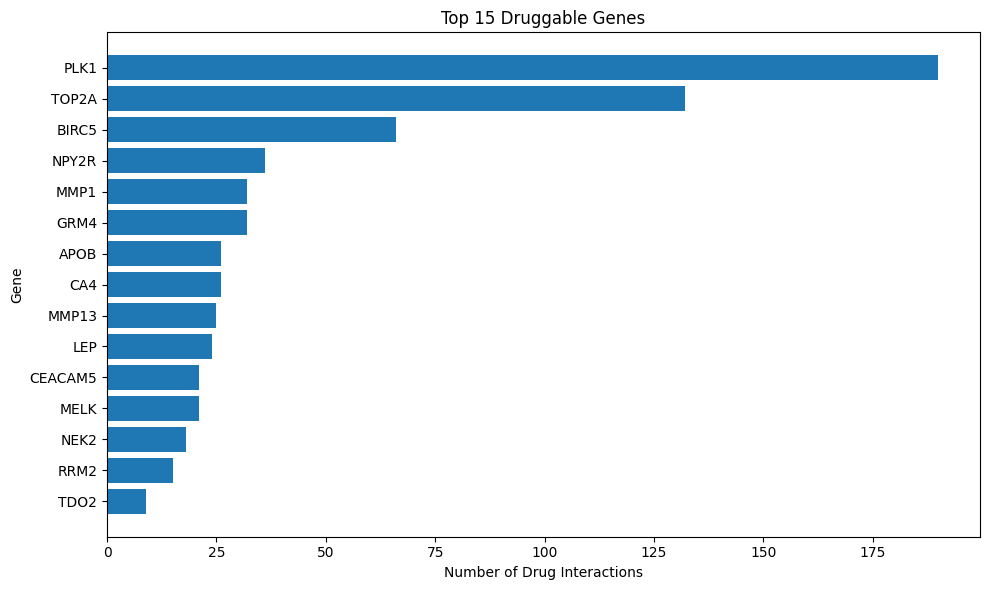

In [0]:
import matplotlib.pyplot as plt

# Top 15 genes
top15_genes = drugs_per_gene.head(15)

plt.figure(figsize=(10,6))

plt.barh(
    top15_genes["Gene"],
    top15_genes["Number_of_Drugs"]
)

plt.xlabel("Number of Drug Interactions")
plt.ylabel("Gene")
plt.title("Top 15 Druggable Genes")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/top15_genes_drug_interactions.png", dpi=300)
plt.show()

## Figure 2. Top drugs targeting multiple differentially expressed genes.

The chart highlights drugs interacting with multiple significantly dysregulated genes.
Drugs targeting several genes may represent stronger candidates for computational drug repurposing studies.

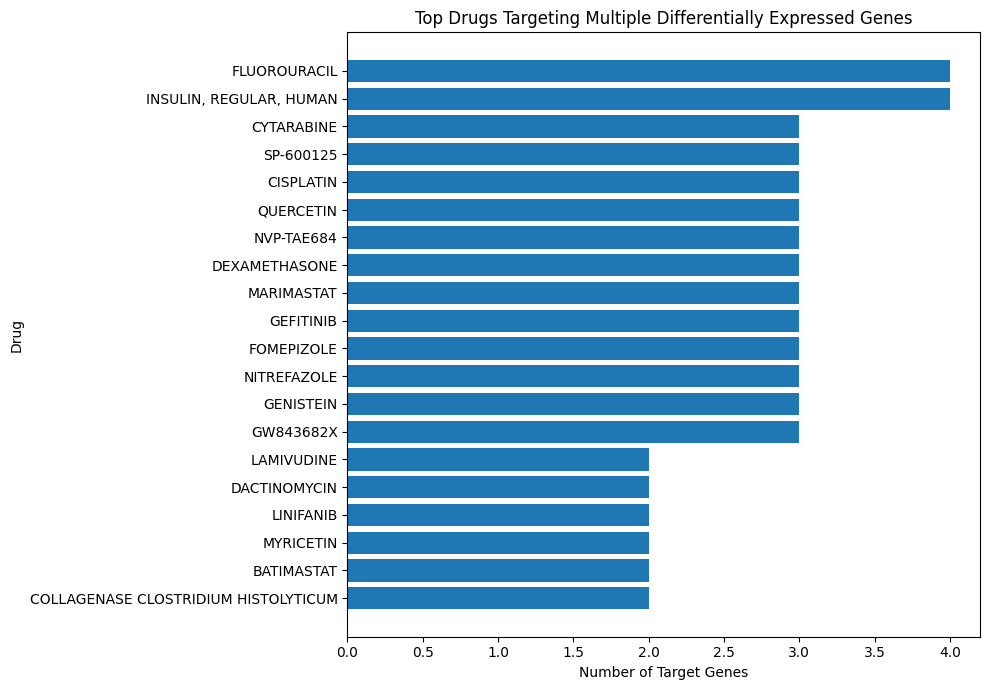

In [0]:
top20_drugs = drug_target_summary.head(20)

plt.figure(figsize=(10,7))

plt.barh(
    top20_drugs["Drug"],
    top20_drugs["Number_of_Genes"]
)

plt.xlabel("Number of Target Genes")
plt.ylabel("Drug")

plt.title("Top Drugs Targeting Multiple Differentially Expressed Genes")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(f"{FIG_DIR}/top20_drugs.png", dpi=300)

plt.show()

## Figure 3. Distribution of drug–gene interaction types.

The interaction types retrieved from DGIdb were summarized to understand the predominant mechanisms of action among identified drug–gene interactions.

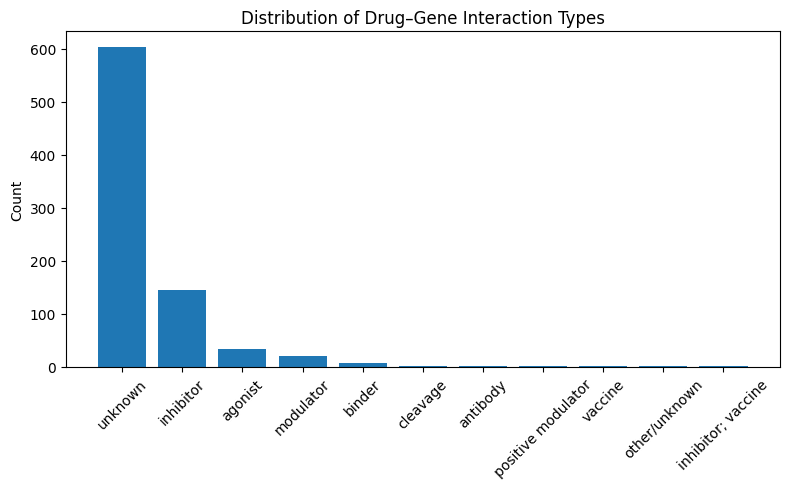

In [0]:
plt.figure(figsize=(8,5))

plt.bar(
    interaction_counts["Interaction_Type"],
    interaction_counts["Count"]
)

plt.xticks(rotation=45)

plt.ylabel("Count")

plt.title("Distribution of Drug–Gene Interaction Types")

plt.tight_layout()

plt.savefig(f"{FIG_DIR}/interaction_types.png", dpi=300)

plt.show()

## Figure 4. Gene–drug interaction network

In [0]:
%pip install networkx

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 53.8 MB/s eta 0:00:00
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


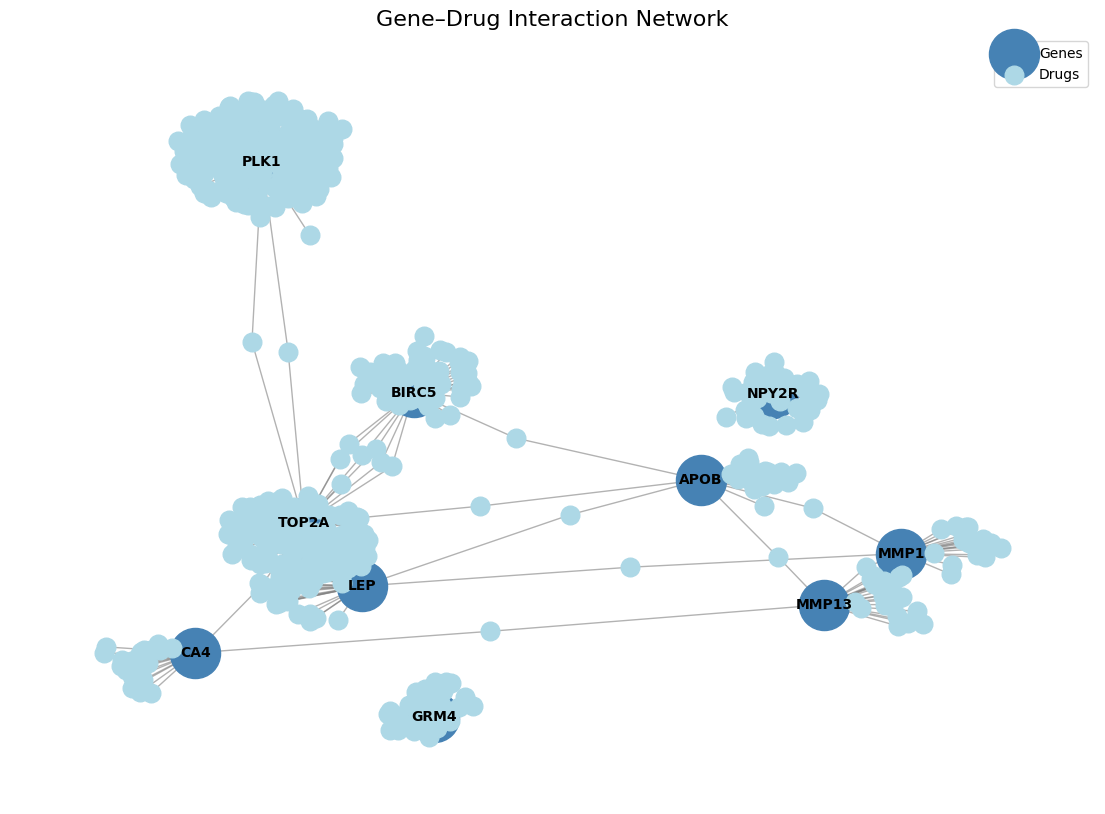

In [0]:
import networkx as nx
import matplotlib.pyplot as plt

# ---------------------------------------
# Figure 4: Gene–Drug Interaction Network
# ---------------------------------------

# Select the 10 genes with the most drug interactions
top_genes = drugs_per_gene.head(10)["Gene"].tolist()

# Keep only interactions involving these genes
network_df = drug_clean_df[drug_clean_df["Gene"].isin(top_genes)]

# Create graph
G = nx.Graph()

# Add edges (Gene <-> Drug)
for _, row in network_df.iterrows():
    G.add_edge(row["Gene"], row["Drug"])

# Separate gene and drug nodes
gene_nodes = network_df["Gene"].unique()
drug_nodes = network_df["Drug"].unique()

# Create layout
plt.figure(figsize=(14,10))
pos = nx.spring_layout(G, k=0.45, seed=42)

# Draw gene nodes
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=gene_nodes,
    node_size=1300,
    node_color="steelblue",
    label="Genes"
)

# Draw drug nodes
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=drug_nodes,
    node_size=180,
    node_color="lightblue",
    label="Drugs"
)

# Draw edges
nx.draw_networkx_edges(
    G,
    pos,
    edge_color="gray",
    alpha=0.6
)

# Label ONLY genes
gene_labels = {gene: gene for gene in gene_nodes}

nx.draw_networkx_labels(
    G,
    pos,
    labels=gene_labels,
    font_size=10,
    font_weight="bold"
)

plt.title("Gene–Drug Interaction Network", fontsize=16)
plt.legend()
plt.axis("off")

# Save figure
plt.savefig(f"{FIG_DIR}/gene_drug_network.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

# Conclusion

This analysis integrated differential gene expression results from TCGA-BRCA (FDR < 0.05, |log2FC| > 1) with DGIdb drug–gene interaction data to identify computational drug repurposing candidates.

* The 50 most upregulated and 50 most downregulated genes were queried against DGIdb in a single GraphQL request.
* For each druggable gene, all known interaction types and sources were kept.
* Candidates were then filtered by direction: drugs that inhibit upregulated genes, or activate downregulated genes, are the ones that could reverse the tumor expression pattern.

**Limitations:** DGIdb lists known interactions, not proven anti-cancer effects. Many interactions have no defined mechanism, some entries are broad drug classes rather than single compounds, and bulk tumor vs normal differences partly reflect tissue composition. Candidates from this analysis are hypotheses that would need literature review and experimental validation.